# 01 - Scraping, EDA, dan Cleaning Komentar YouTube

Menggantikan bagian scraping + preprocessing pada `worker.py` lama, **tanpa database dan tanpa API key**.

Alur:
1. Setup
2. Scraping komentar (library `youtube-comment-downloader`) + judul video (oEmbed YouTube)
3. EDA data mentah
4. Cleaning langkah demi langkah
5. Filter & deduplikasi
6. EDA setelah cleaning
7. Simpan **data siap prediksi** (`data_siap_predict.csv`)
8. *(Opsional)* Prediksi dengan model dari notebook `02_training_model.ipynb`

Prinsip penting: fungsi `clean_text` di notebook ini **identik** dengan yang dipakai saat training. Jika cleaning berbeda,
model menerima teks yang bentuknya tidak pernah ia lihat dan prediksinya tidak bisa dipercaya.

## 1. Setup

In [1]:
%pip install -q youtube-comment-downloader emoji nltk wordcloud anyascii

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import time
from collections import Counter
from itertools import islice

import numpy as np
import pandas as pd
import requests
from wordcloud import WordCloud
from youtube_comment_downloader import SORT_BY_POPULAR, SORT_BY_RECENT, YoutubeCommentDownloader

pd.set_option("display.max_colwidth", 120)

import matplotlib.pyplot as plt
import seaborn as sns

# Palet konsisten di semua notebook: biru = komentar normal, oranye = promosi judi
WARNA_LABEL = {0: "#2a78d6", 1: "#eb6834"}
NAMA_LABEL = {0: "Normal (0)", 1: "Promosi judi (1)"}
WARNA_MODEL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
})

In [3]:
import os
import re
import unicodedata
import urllib.request

import emoji
import nltk
import pandas as pd
from anyascii import anyascii
from nltk.corpus import stopwords

nltk.download("stopwords", quiet=True)
STOPWORDS_ID = set(stopwords.words("indonesian"))

RE_URL = re.compile(r"https?://\S+|www\.\S+")
RE_MENTION_HASHTAG = re.compile(r"[@#]\w+")
RE_YT_EMOJI = re.compile(r":([a-z0-9]+(?:-[a-z0-9]+)+):")      # emoji khusus YouTube, mis. :face-blue-smiling:
RE_RI_RUN = re.compile("[\U0001F1E6-\U0001F1FF]{3,}")           # >= 3 huruf bendera berurutan = kata, bukan bendera
RE_NON_ASCII_RUN = re.compile(r"[^\x00-\x7f]+")
RE_ASCII_PUNCT = re.compile(r"[!-/:-@\[-^`{-~]")                 # tanda baca ASCII, kecuali "_" (dipakai token)
RE_SPACED = re.compile(r"\b(?:[a-z0-9] ){3,}[a-z0-9]\b")        # "p l u t o 8 8" (minimal 4 karakter)
RE_DOLAR_HURUF = re.compile(r"(?<=[a-z])\$|\$(?=[a-z])")   # "$" menempel huruf dipakai sebagai "s"
RE_LEET = re.compile(r"^[a-z]+[0-9]+[a-z][a-z0-9]*$")           # angka di tengah huruf: m4xw1n, sl0t

# Penanda trik penyamaran. Disimpan di KOLOM TERPISAH ("sinyal"), bukan ditempel ke teks, supaya teks bersih
# tetap enak dibaca. Saat training kolom ini menjadi fitur biner di samping TF-IDF teks.
SINYAL = {
    "xxfancy": "huruf gaya: bold/italic/fullwidth, small caps, huruf-emoji (huruf dalam kotak), huruf bendera berurutan",
    "xxhomoglyph": "huruf aksara lain yang bentuknya mirip Latin (Cyrillic, Yunani, Armenia, Cherokee, ...)",
    "xxspaced": "huruf yang dipisah spasi, mis. 'P L U T O 8 8'",
    "xxdecor": "simbol non-ASCII selain emoji, mis. blok, bintang, kurung dekoratif",
    "xxleet": "leetspeak: angka di tengah huruf (m4xw1n, sl0t - teksnya TIDAK diubah) atau $ sebagai s",
    "xxinvisible": "karakter tak terlihat (zero-width space, dsb.) yang diselipkan untuk memecah kata",
}

# ---------------------------------------------------------------------------------------------
# Tabel homoglif: Unicode confusables (TR39) = pemetaan resmi karakter yang BENTUKNYA mirip.
# Hanya aksara yang lazim dipakai menyamar yang diambil; Arab, CJK, dsb. tidak dipetakan
# supaya komentar asli berbahasa/beraksara lain tidak berubah jadi huruf Latin acak.
# ---------------------------------------------------------------------------------------------
URL_CONFUSABLES = "https://www.unicode.org/Public/security/latest/confusables.txt"
AKSARA_PENYAMAR = {"CYRILLIC", "GREEK", "ARMENIAN", "CHEROKEE", "LISU", "COPTIC", "LATIN", "MODIFIER",
                   "SCRIPT", "DOUBLE-STRUCK", "BLACK-LETTER", "MATHEMATICAL", "FULLWIDTH", "ROMAN"}
AKSARA_LATIN_GAYA = {"LATIN", "MODIFIER", "SCRIPT", "DOUBLE-STRUCK", "BLACK-LETTER", "MATHEMATICAL",
                     "FULLWIDTH", "ROMAN"}
# Karakter tak terlihat yang bisa diselipkan di tengah kata: zero-width space/joiner, word joiner, BOM, soft hyphen
KARAKTER_TAK_TERLIHAT = {chr(k) for k in (0x200B, 0x200C, 0x200D, 0x2060, 0xFEFF, 0x00AD)}
# Angka gaya: angka dalam lingkaran (hitam), kurung, titik, superscript, dsb. Angka aksara lain (Arab, Devanagari)
# TIDAK diubah karena bisa jadi bagian teks asli.
VARIATION_SELECTOR = {chr(0xFE0E), chr(0xFE0F)}
AKSARA_ANGKA_GAYA = {"DINGBAT", "CIRCLED", "NEGATIVE", "PARENTHESIZED", "DIGIT", "SUPERSCRIPT", "SUBSCRIPT",
                     "DOUBLE", "FULLWIDTH", "MATHEMATICAL"}
# Pelengkap: kemiripan visual yang TIDAK ada di confusables Unicode tetapi ditemukan lewat inventaris karakter
# (mis. lambda di "lambda-lexis17", increment/delta di "$<delta>MP<delta>H"). Tambahkan di sini jika menemukan trik baru.
TAMBAHAN_VISUAL = {chr(k): v for k, v in {
    0x3BB: "a", 0x39B: "a", 0x2206: "a", 0x394: "a",                # lambda, Lambda, increment, Delta
}.items()}
HOMOGLYPH_CADANGAN = {chr(k): v for k, v in {  # dipakai jika confusables.txt gagal diunduh
    0x430: "a", 0x435: "e", 0x43E: "o", 0x440: "p", 0x441: "c", 0x443: "y",     # Cyrillic
    0x445: "x", 0x43A: "k", 0x43C: "m", 0x442: "t", 0x43D: "h", 0x432: "b",
    0x456: "i", 0x458: "j", 0x455: "s", 0x501: "d",
    0x3B1: "a", 0x3BF: "o", 0x3B5: "e", 0x3B9: "i", 0x3BA: "k", 0x3BD: "v",     # Yunani
    0x3C1: "p", 0x3C4: "t", 0x3C5: "u", 0x3C7: "x",
}.items()}


def aksara(c):
    return unicodedata.name(c, "UNKNOWN").split()[0]


def muat_confusables(path="confusables.txt"):
    peta = dict(HOMOGLYPH_CADANGAN)
    try:
        if not os.path.exists(path):
            urllib.request.urlretrieve(URL_CONFUSABLES, path)
        with open(path, encoding="utf-8-sig") as f:
            for baris in f:
                baris = baris.split("#")[0].strip()
                if not baris:
                    continue
                src, tgt = [x.strip() for x in baris.split(";")[:2]]
                src = "".join(chr(int(h, 16)) for h in src.split())
                tgt = "".join(chr(int(h, 16)) for h in tgt.split())
                if (len(src) == 1 and not src.isascii() and tgt.isascii() and tgt.isalnum()
                        and aksara(src) in AKSARA_PENYAMAR):
                    peta[src] = tgt.lower()
    except Exception as e:
        print(f"confusables.txt tidak tersedia ({e}) - memakai {len(peta)} homoglif bawaan")
    peta.update(TAMBAHAN_VISUAL)
    return peta


HOMOGLYPH = muat_confusables()
print(f"Tabel homoglif: {len(HOMOGLYPH):,} karakter")


def _emoji_ke_token(e, data):
    nama = data["en"].strip(":").lower()
    nama = re.sub(r"_?(medium-light|medium-dark|light|medium|dark)_skin_tone", "", nama)
    return " emo_" + re.sub(r"[^a-z0-9]+", "_", nama).strip("_") + " "


def proses_teks(text, remove_stopwords=True, trace=False):
    """Cleaning lengkap. Mengembalikan (teks_bersih, sinyal, karakter_tak_dikenal, langkah)."""
    sinyal, tak_dikenal, langkah = set(), [], []

    def catat(nama, t):
        if trace:
            langkah.append((nama, t))

    if not isinstance(text, str):
        return "", sinyal, tak_dikenal, langkah
    t = text
    catat("0. asli", t)

    # 1. Huruf gaya (bold, italic, fullwidth, circled) -> huruf biasa dengan NFKC
    if any(not c.isascii() and unicodedata.normalize("NFKC", c).isascii()
           and unicodedata.normalize("NFKC", c).isalnum() for c in t):
        sinyal.add("xxfancy")
    t = unicodedata.normalize("NFKC", t)
    t = RE_URL.sub(" ", t)
    t = RE_MENTION_HASHTAG.sub(" ", t).replace("_", " ")
    catat("1. NFKC, hapus URL/mention", t)

    # 2. Huruf-emoji -> huruf: huruf dalam kotak hitam (U+1F150-1F189) dan huruf bendera berurutan
    #    (>= 3, agar pasangan bendera seperti Indonesia tetap dibaca sebagai bendera)
    def ri(m):
        return "".join(chr(ord(c) - 0x1F1E6 + ord("a")) for c in m.group())
    t2 = RE_RI_RUN.sub(ri, t)
    t2 = "".join(anyascii(c) if 0x1F150 <= ord(c) <= 0x1F189 else c for c in t2)
    if t2 != t:
        sinyal.add("xxfancy")
    t = t2
    catat("2. huruf-emoji -> huruf", t)

    # 3. Emoji -> token (TIDAK dihapus): kantong uang -> emo_money_bag
    t = RE_YT_EMOJI.sub(lambda m: " emo_" + m.group(1).replace("-", "_") + " ", t)
    t = emoji.replace_emoji(t, replace=_emoji_ke_token)
    catat("3. emoji -> token", t)

    # 4. Karakter tak terlihat dibuang TANPA spasi (memecah kata: "plu<ZWSP>to" -> "pluto"),
    #    lalu homoglif -> Latin (tabel confusables) dan huruf kecil
    if any(c in KARAKTER_TAK_TERLIHAT for c in t):
        sinyal.add("xxinvisible")
    t = "".join(c for c in t if c not in KARAKTER_TAK_TERLIHAT and c not in VARIATION_SELECTOR)
    for c in set(t):
        if c in HOMOGLYPH:
            sinyal.add("xxfancy" if aksara(c) in AKSARA_LATIN_GAYA else "xxhomoglyph")
    t = "".join(HOMOGLYPH.get(c, c) for c in t).lower()
    t2 = RE_DOLAR_HURUF.sub("s", t)            # "$ampah" -> "sampah" ("$100" tidak berubah)
    if t2 != t:
        sinyal.add("xxleet")
    t = t2
    catat("4. homoglif -> Latin", t)

    # 5. Aksen dibuang (cafe' -> cafe); huruf Latin lain (small caps, o-garis) -> ASCII;
    #    angka gaya (angka dalam lingkaran hitam, dsb.) -> angka biasa; tanda baca tipografis -> tanda baca ASCII
    t = "".join(c for c in unicodedata.normalize("NFKD", t) if not unicodedata.combining(c))
    hasil = []
    for c in t:
        if c.isascii():
            hasil.append(c)
        elif aksara(c) == "LATIN":
            if "SMALL CAPITAL" in unicodedata.name(c, "") or unicodedata.name(c, "").startswith("LATIN LETTER"):
                sinyal.add("xxfancy")
            hasil.append(anyascii(c).lower())
        elif unicodedata.digit(c, None) is not None and aksara(c) in AKSARA_ANGKA_GAYA:
            sinyal.add("xxfancy")
            hasil.append(str(unicodedata.digit(c)))
        elif 0x2010 <= ord(c) <= 0x205E and unicodedata.category(c)[0] == "P":
            hasil.append(" ")  # blok General Punctuation (kutip miring, em dash, elipsis) = tanda baca biasa
        else:
            hasil.append(c)
    t = "".join(hasil)
    catat("5. aksen, Latin lain, angka gaya", t)

    # 6. Sisa non-ASCII TIDAK dihapus diam-diam: huruf aksara lain -> xxscript_<aksara>, simbol -> xxdecor
    def sisa(m):
        run = m.group()
        tak_dikenal.extend(run)
        huruf = [c for c in run if unicodedata.category(c)[0] in "LN"]
        if huruf:
            return f" xxscript_{aksara(huruf[0]).lower().replace('-', '_')} "
        if any(unicodedata.category(c)[0] in "SP" for c in run):
            sinyal.add("xxdecor")
        return " "
    t = RE_NON_ASCII_RUN.sub(sisa, t)
    catat("6. sisa non-ASCII -> token", t)

    # 7. Tanda baca ASCII dihapus, spasi dirapikan
    t = re.sub(r"\s+", " ", RE_ASCII_PUNCT.sub(" ", t)).strip()
    catat("7. hapus tanda baca ASCII", t)

    # 8. Gabung huruf yang dispasi: "p l u t o 8 8" -> "pluto88"
    t2 = RE_SPACED.sub(lambda m: m.group().replace(" ", ""), t)
    if t2 != t:
        sinyal.add("xxspaced")
    t = t2
    catat("8. gabung huruf dispasi", t)

    # 9. Leetspeak dibiarkan apa adanya (m4xw1n tetap m4xw1n), hanya ditandai
    tokens = t.split()
    if any(RE_LEET.match(tok) for tok in tokens):
        sinyal.add("xxleet")

    # 10. Stopword Bahasa Indonesia
    if remove_stopwords:
        tokens = [tok for tok in tokens if tok not in STOPWORDS_ID]
    catat("10. hapus stopword", " ".join(tokens))

    hasil_akhir = " ".join(tokens)
    catat("11. kolom sinyal (terpisah)", " ".join(sorted(sinyal)) or "-")
    return hasil_akhir, sinyal, tak_dikenal, langkah


def clean_text(text, remove_stopwords=True):
    """Teks bersih yang enak dibaca (tanpa token sinyal). Sinyal: obfuscation_signals()."""
    return proses_teks(text, remove_stopwords)[0]


def light_clean(text):
    """Cleaning minimal untuk model karakter n-gram: huruf kecil, URL, mention. Non-ASCII DIBIARKAN."""
    text = RE_URL.sub(" ", str(text).lower())
    text = RE_MENTION_HASHTAG.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()


def siapkan_input(texts):
    """Input model (training maupun prediksi): DataFrame berkolom text_clean, sinyal, text_min."""
    texts = pd.Series(texts) if not isinstance(texts, pd.Series) else texts
    hasil = texts.apply(proses_teks)
    return pd.DataFrame({
        "text_clean": hasil.str[0],
        "sinyal": hasil.str[1].apply(lambda s: " ".join(sorted(s))),
        "text_min": texts.apply(light_clean),
    }, index=texts.index)


def obfuscation_signals(text):
    return proses_teks(text)[1]


def karakter_tak_dikenal(text):
    return proses_teks(text)[2]


def tampilkan_langkah(text):
    for nama, isi in proses_teks(text, trace=True)[3]:
        print(f"{nama:30s} | {isi}")
    print()

Tabel homoglif: 1,276 karakter


### Konfigurasi

Ganti `VIDEO_IDS` dengan video yang ingin diperiksa. ID video adalah bagian setelah `watch?v=` pada URL YouTube.
Contoh di bawah adalah video dari dataset Kaggle yang (saat notebook ini dibuat) masih memuat komentar promosi judi.

In [4]:
VIDEO_IDS = ["ufS5vDKnIhM", "gRjWM8jPIPw", "VXqMJqP7mvk"]
MAX_KOMENTAR_PER_VIDEO = 300           # None = ambil semua (bisa lama untuk video populer)
URUTAN = SORT_BY_RECENT                # atau SORT_BY_POPULAR
MIN_KARAKTER = 10                      # komentar bersih yang lebih pendek dari ini dibuang
MAX_KARAKTER = None                    # worker lama memakai 70; None = tanpa batas atas (lihat bagian 5)

## 2. Scraping

- **Komentar**: `youtube-comment-downloader` membaca komentar langsung dari halaman YouTube, tanpa API key.
- **Judul & channel**: endpoint publik [oEmbed](https://oembed.com/) YouTube, juga tanpa API key.
  (Worker lama memakai YouTube Data API yang butuh key dan kuota.)

In [5]:
def info_video(video_id):
    try:
        r = requests.get("https://www.youtube.com/oembed",
                         params={"url": f"https://www.youtube.com/watch?v={video_id}", "format": "json"}, timeout=15)
        r.raise_for_status()
        j = r.json()
        return {"video_id": video_id, "title": j.get("title"), "channel_name": j.get("author_name")}
    except Exception as e:
        print(f"[{video_id}] gagal mengambil info video: {e}")
        return {"video_id": video_id, "title": None, "channel_name": None}


def scrape_komentar(video_id, limit=None, sort_by=SORT_BY_RECENT):
    downloader = YoutubeCommentDownloader()
    hasil = []
    try:
        it = downloader.get_comments_from_url(f"https://www.youtube.com/watch?v={video_id}", sort_by=sort_by)
        for c in islice(it, limit):
            hasil.append({
                "video_id": video_id,
                "comment_id": c["cid"],
                "author": c["author"].lstrip("@"),
                "text": c["text"],
                "votes": c.get("votes", "0"),
                "is_reply": c.get("reply", False),
                "waktu_relatif": c.get("time"),
                "time_parsed": c.get("time_parsed"),
            })
    except Exception as e:
        print(f"[{video_id}] gagal scraping: {e}")
    return hasil

In [6]:
semua, info = [], []
for vid in VIDEO_IDS:
    t0 = time.time()
    info.append(info_video(vid))
    kom = scrape_komentar(vid, MAX_KOMENTAR_PER_VIDEO, URUTAN)
    semua.extend(kom)
    print(f"[{vid}] {len(kom):4d} komentar dalam {time.time() - t0:.1f}s - {info[-1]['title']}")

df_video = pd.DataFrame(info)
df_raw = pd.DataFrame(semua)

[ufS5vDKnIhM]  300 komentar dalam 7.1s - MITSUBISHI TRITON ULTIMATE AT | Definisi Pria Jago Di Kantor dan Di Lapangan


[gRjWM8jPIPw]  300 komentar dalam 7.2s - MR. BOND, MOBIL ANDA SUDAH SIAP | ASTON MARTIN DB12


[VXqMJqP7mvk]  300 komentar dalam 7.6s - HP TERGILA yang dijual RESMI di INDONESIA! - Huawei Mate XT!


Jika scraping gagal (mis. YouTube memblokir IP server Colab), notebook tetap bisa dipelajari: sel berikut memakai
**komentar mentah dari dataset Kaggle** sebagai pengganti.

In [7]:
if df_raw.empty:
    import glob
    import kagglehub
    print("Scraping kosong -> memakai sampel komentar mentah dari dataset Kaggle sebagai pengganti")
    p = kagglehub.dataset_download("yaemico/judionline")
    k = pd.read_csv(glob.glob(os.path.join(p, "*.csv"))[0]).sample(900, random_state=0)
    df_raw = pd.DataFrame({"video_id": k["video_id"], "comment_id": [f"kaggle_{i}" for i in k.index],
                           "author": k["author"], "text": k["komentar"], "votes": "0", "is_reply": False,
                           "waktu_relatif": None, "time_parsed": np.nan})
    df_video = k[["video_id", "title", "channel_name"]].drop_duplicates("video_id")

df_raw = df_raw.merge(df_video, on="video_id", how="left")
# time_parsed dihitung library dari teks relatif ("1 tahun yang lalu") -> hanya perkiraan kasar
df_raw["published_at"] = pd.to_datetime(df_raw["time_parsed"], unit="s", utc=True)
df_raw.to_csv("komentar_mentah.csv", index=False)
print(df_raw.shape)
df_raw.head()

(900, 11)


,video_id,comment_id,author,text,votes,is_reply,waktu_relatif,time_parsed,title,channel_name,published_at
0,ufS5vDKnIhM,UgwcaAd6uEAYXWRfOsl4AaABAg,ayangwati9332,"Udah dapat sih yg terbaru, selama ini belum ada kendala sih bawa muatan",0,False,1 bulan yang lalu,1.790502e+09,MITSUBISHI TRITON ULTIMATE AT | Definisi Pria Jago Di Kantor dan Di Lapangan,Motomobi,2026-09-27 09:42:33.235838890+00:00
1,ufS5vDKnIhM,UgwgUPL27H80cTO4wch4AaABAg,Sniper-GTO,Mobil ini kalo di upgrade Tampilan pasti GANTENG Bangat.🎉,0,False,1 bulan yang lalu,1.790502e+09,MITSUBISHI TRITON ULTIMATE AT | Definisi Pria Jago Di Kantor dan Di Lapangan,Motomobi,2026-09-27 09:42:33.238723993+00:00
2,ufS5vDKnIhM,Ugx-gBe2PyGQXKi2jex4AaABAg,Zidan-y1p,Triton udah teruji di balap tingkat dunia Rally Dakar,1,False,3 bulan yang lalu,1.785145e+09,MITSUBISHI TRITON ULTIMATE AT | Definisi Pria Jago Di Kantor dan Di Lapangan,Motomobi,2026-07-27 09:42:33.240654945+00:00
3,ufS5vDKnIhM,UgysQujcgesVRPDhXU14AaABAg,fertianeka2266,sama hilux type v terbaru enakan mana om ...jujur yah,0,False,3 bulan yang lalu,1.785145e+09,MITSUBISHI TRITON ULTIMATE AT | Definisi Pria Jago Di Kantor dan Di Lapangan,Motomobi,2026-07-27 09:42:33.242378950+00:00
4,ufS5vDKnIhM,UgyW9Fa2MqQvgs4LPoR4AaABAg,yusninurrahman6214,❤nice ride kalo matic❤aplg dpt foglamp mcm panther 2.5 di persegi❤,1,False,4 bulan yang lalu,1.782553e+09,MITSUBISHI TRITON ULTIMATE AT | Definisi Pria Jago Di Kantor dan Di Lapangan,Motomobi,2026-06-27 09:42:33.244033098+00:00


## 3. EDA data mentah

In [8]:
print(f"Jumlah komentar : {len(df_raw):,}")
print(f"Jumlah video    : {df_raw['video_id'].nunique()}")
print(f"Jumlah author   : {df_raw['author'].nunique():,}")
print(f"Balasan (reply) : {df_raw['is_reply'].mean():.1%}")
print(f"Teks duplikat   : {df_raw['text'].duplicated().sum():,}")
print()
df_raw.isna().sum().to_frame("missing")

Jumlah komentar : 900
Jumlah video    : 3
Jumlah author   : 854
Balasan (reply) : 6.4%
Teks duplikat   : 29



,missing
video_id,0
comment_id,0
author,0
text,0
votes,0
is_reply,0
waktu_relatif,0
time_parsed,0
title,0
channel_name,0


In [9]:
per_video = df_raw.groupby(["video_id", "title"]).agg(
    komentar=("text", "size"), author=("author", "nunique"), duplikat=("text", lambda s: s.duplicated().sum()))
per_video

,,komentar,author,duplikat
video_id,title,,,
VXqMJqP7mvk,HP TERGILA yang dijual RESMI di INDONESIA! - Huawei Mate XT!,300,282,1
gRjWM8jPIPw,"MR. BOND, MOBIL ANDA SUDAH SIAP | ASTON MARTIN DB12",300,286,6
ufS5vDKnIhM,MITSUBISHI TRITON ULTIMATE AT | Definisi Pria Jago Di Kantor dan Di Lapangan,300,290,12


### Tanda-tanda penyamaran pada teks mentah

Sebelum dibersihkan, cek berapa komentar yang memakai trik non-ASCII. Ini **bukan** label, hanya indikasi awal
(huruf fancy, homoglif, huruf dispasi, simbol dekoratif - lihat `SINYAL`).

In [10]:
df_raw["n_char"] = df_raw["text"].str.len()
df_raw["n_emoji"] = df_raw["text"].apply(emoji.emoji_count)
df_raw["n_non_ascii"] = df_raw["text"].apply(lambda t: sum(not c.isascii() for c in str(t)))
df_raw["sinyal"] = df_raw["text"].apply(lambda t: sorted(obfuscation_signals(t)))

prevalensi = pd.Series({k: df_raw["sinyal"].apply(lambda s: k in s).mean() for k in SINYAL})
print("Proporsi komentar mentah dengan tiap trik:")
print(prevalensi.map("{:.1%}".format).to_string())
print(f"\nKomentar dengan minimal satu trik: {(df_raw['sinyal'].str.len() > 0).mean():.1%}")

df_raw.loc[df_raw["sinyal"].str.len() > 0, ["text", "sinyal"]].head(10)

Proporsi komentar mentah dengan tiap trik:
xxfancy        12.7%
xxhomoglyph     0.9%
xxspaced        4.3%
xxdecor         1.6%
xxleet          2.4%
xxinvisible     0.6%

Komentar dengan minimal satu trik: 18.6%


,text,sinyal
12,"Semoga om mobi baca,,,mobil ini udh ada kekurangannya om,,di prushan besar batu bara di kaltim(kutim), mobil ini lem...",[xxleet]
42,"@betterisi439 under 100k biasanya, tergantung ada pungli tipis2 atau nggak wkwkw atau ada kesalahan dari kitanya, k...",[xxleet]
83,mancing mnatab hanya di 𝒉𝒐𝒌𝒊777 bosku,[xxfancy]
84,Emang rekomendasi 07:07 lokasinya bisa langsung di cari di google ada di 【H】【o】【k】【i】【7】【7】【7】,"[xxdecor, xxspaced]"
85,ikan patin ikan sapu sapu 𝒉𝒐𝒌𝒊777 dijamin paling jitu,[xxfancy]
88,​ @notme_ns stir nya berat gak om?,[xxinvisible]
90,@MuhammadFauzi-dg5vj saya kebetulan kerja di kalimantan …\nJujur faktanya lebih banyak hilux yang kena masalah di ...,[xxleet]
91,"​ @Spacespace1444 pantesan di balai lelang ibid bayak hilux tahun muda sudah dilelang,, sedangkan triton kebanyakan ...",[xxinvisible]
92,"​​ @Spacespace1444 Triton facelift 2024 ini ada masalah serius di fuel pump nya, macam cacat pabrik . Udah pakai min...",[xxinvisible]
93,​ @pandewayan3286 saya user ke 2 merk itu.kenyamanan & kaki2.Hilux lebih unggul.soal tenaga/responsif nya.Triton jag...,[xxinvisible]


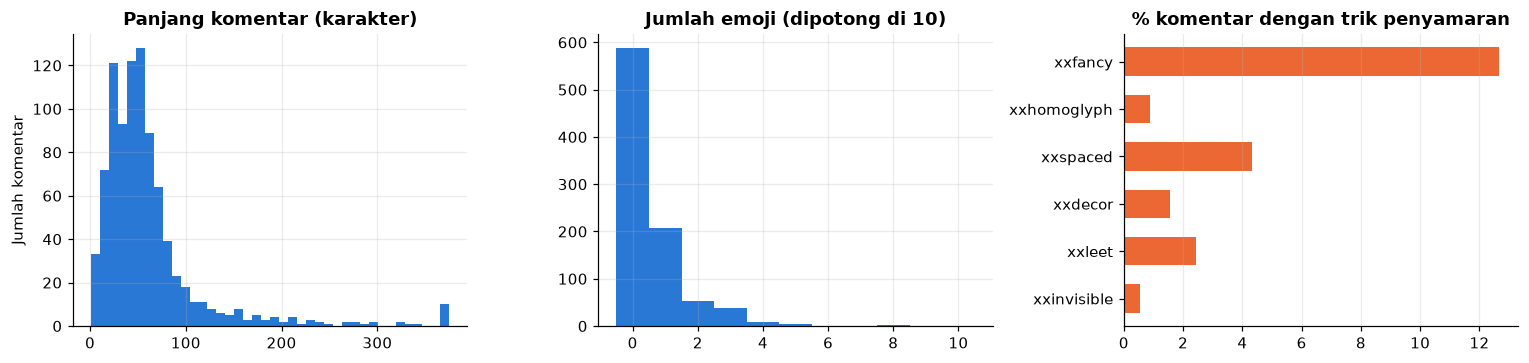

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].hist(df_raw["n_char"].clip(upper=df_raw["n_char"].quantile(0.99)), bins=40, color=WARNA_MODEL[0])
axes[0].set_title("Panjang komentar (karakter)")
axes[1].hist(df_raw["n_emoji"].clip(upper=10), bins=np.arange(12) - 0.5, color=WARNA_MODEL[0])
axes[1].set_title("Jumlah emoji (dipotong di 10)")
axes[2].barh(list(SINYAL)[::-1], prevalensi.values[::-1] * 100, color=WARNA_LABEL[1], height=0.6)
axes[2].set_title("% komentar dengan trik penyamaran")
axes[2].grid(axis="y", visible=False)
axes[0].set_ylabel("Jumlah komentar")
plt.tight_layout()
plt.show()

In [12]:
# Author yang berkomentar berkali-kali sering kali akun bot
top_author = df_raw["author"].value_counts().head(10)
top_author.to_frame("jumlah komentar")

,jumlah komentar
author,
JERDiEgomezPAPVTVNGAN,5
RaimonTenowi,4
Ikayogaprastawa27,3
noname-jb4rz,3
trengginascreator330,3
yusninurrahman6214,2
ainafitri3989,2
auliasyari1782,2
kurniawanayyas6362,2


## 4. Cleaning langkah demi langkah

Prinsip untuk kasus judi online: **non-ASCII jangan dibuang begitu saja, tetapi juga jangan dipakai mentah.**
Tidak ada karakter yang dihapus diam-diam:

| Jenis karakter | Diubah menjadi | Langkah |
|---|---|---|
| huruf gaya (bold, italic, fullwidth, circled) | huruf biasa + `xxfancy` | 1 (NFKC) |
| huruf-emoji (huruf dalam kotak, huruf bendera berurutan) | huruf biasa + `xxfancy` | 2 |
| emoji | token `emo_<nama>`, mis. `emo_money_bag`, `emo_slot_machine` | 3 |
| karakter tak terlihat (zero-width space, dsb.) di tengah kata | dibuang tanpa spasi (`plu?to` -> `pluto`) + `xxinvisible` | 4 |
| huruf Cyrillic/Yunani/Armenia/Cherokee yang mirip Latin | huruf Latin + `xxhomoglyph` (tabel `confusables.txt` resmi Unicode) | 4 |
| kemiripan visual di luar tabel Unicode, ditemukan lewat inventaris (lambda/delta sebagai `a`) | huruf Latin + `xxhomoglyph` (`TAMBAHAN_VISUAL`) | 4 |
| `$` menempel huruf (`$ampah`) | `s` + `xxleet` (`$100` tidak berubah) | 4 |
| small caps, huruf beraksen | huruf biasa (`xxfancy` untuk small caps) | 5 |
| angka gaya (angka dalam lingkaran hitam, dsb.) | angka biasa + `xxfancy` | 5 |
| tanda baca tipografis (kutip miring, em dash) | spasi, **tanpa** sinyal (umum di keyboard HP) | 5 |
| huruf aksara lain (Arab, Jepang, Vai, ...) | token `xxscript_<aksara>` + dicatat di inventaris | 6 |
| simbol dekoratif (blok, kurung, bintang non-emoji) | spasi + `xxdecor` + dicatat di inventaris | 6 |
| tanda baca ASCII | spasi | 7 |
| huruf dispasi `P L U T O 8 8` | `pluto88` + `xxspaced` | 8 |
| leetspeak `m4xw1n` | **tetap** `m4xw1n` + `xxleet` | 9 |

Semua penanda `xx...` (kecuali `xxscript_<aksara>` yang menggantikan karakter di tempatnya) disimpan di **kolom `sinyal`
terpisah**, bukan ditempel ke teks. Jadi `cleaned_text` tetap enak dibaca, dan model memakai kedua kolom sebagai fitur.

Leetspeak sengaja tidak dinormalisasi: bentuk `m4xw1n` sendiri sudah pola spam. Normalisasi leet baru diperlukan nanti
untuk NER, dan sebaiknya disimpan di kolom terpisah.

Bukti bahwa cara ini lebih baik daripada "buang semua" atau "biarkan mentah" ada di bagian 7 notebook 02.

In [13]:
# tampilkan_langkah() didefinisikan di sel cleaning di atas
contoh = df_raw.loc[df_raw["sinyal"].str.len() > 0, "text"].head(2).tolist()
contoh += ["Mantap bang! :face-blue-smiling: cek https://contoh.com @temen #viral \U0001f1ee\U0001f1e9",
           "gas main di \u0430l\u0435xis17 \u2b50 P L U T O 8 8 \u2b50 \U0001f4b0\U0001f3b0",
           "\U0001f170\U0001f17b\U0001f174\U0001f187\U0001f178\U0001f182 17 \u1d0d\u1d00x\u1d21\u026a\u0274 sl\u0585t m4xw1n",
           "masyaallah \u0645\u0627\u0634\u0627\u0621 \u0627\u0644\u0644\u0647 \ua5e5MANUT88\ua5e5"]
for t in contoh:
    tampilkan_langkah(t)

0. asli                        | Semoga om mobi baca,,,mobil ini udh ada kekurangannya om,,di prushan besar batu bara di kaltim(kutim), mobil ini lemah di spring om,,baru masuk di tambang skitr 6bln,udh bnyk spring2nya yg patah,,padhl msh di medan jln berbatu yg msh standar,,tp yah bgtulah,,,lbh layak hilux🙏
1. NFKC, hapus URL/mention     | Semoga om mobi baca,,,mobil ini udh ada kekurangannya om,,di prushan besar batu bara di kaltim(kutim), mobil ini lemah di spring om,,baru masuk di tambang skitr 6bln,udh bnyk spring2nya yg patah,,padhl msh di medan jln berbatu yg msh standar,,tp yah bgtulah,,,lbh layak hilux🙏
2. huruf-emoji -> huruf        | Semoga om mobi baca,,,mobil ini udh ada kekurangannya om,,di prushan besar batu bara di kaltim(kutim), mobil ini lemah di spring om,,baru masuk di tambang skitr 6bln,udh bnyk spring2nya yg patah,,padhl msh di medan jln berbatu yg msh standar,,tp yah bgtulah,,,lbh layak hilux🙏
3. emoji -> token              | Semoga om mobi baca,,,mobil ini udh a

0. asli                        | 🅰🅻🅴🆇🅸🆂 17 ᴍᴀxᴡɪɴ slօt m4xw1n
1. NFKC, hapus URL/mention     | 🅰🅻🅴🆇🅸🆂 17 ᴍᴀxᴡɪɴ slօt m4xw1n
2. huruf-emoji -> huruf        | ALEXIS 17 ᴍᴀxᴡɪɴ slօt m4xw1n
3. emoji -> token              | ALEXIS 17 ᴍᴀxᴡɪɴ slօt m4xw1n
4. homoglif -> Latin           | alexis 17 ᴍᴀxwiɴ slot m4xw1n
5. aksen, Latin lain, angka gaya | alexis 17 maxwin slot m4xw1n
6. sisa non-ASCII -> token     | alexis 17 maxwin slot m4xw1n
7. hapus tanda baca ASCII      | alexis 17 maxwin slot m4xw1n
8. gabung huruf dispasi        | alexis 17 maxwin slot m4xw1n
10. hapus stopword             | alexis 17 maxwin slot m4xw1n
11. kolom sinyal (terpisah)    | xxfancy xxhomoglyph xxleet

0. asli                        | masyaallah ماشاء الله ꗥMANUT88ꗥ
1. NFKC, hapus URL/mention     | masyaallah ماشاء الله ꗥMANUT88ꗥ
2. huruf-emoji -> huruf        | masyaallah ماشاء الله ꗥMANUT88ꗥ
3. emoji -> token              | masyaallah ماشاء الله ꗥMANUT88ꗥ
4. homoglif -> Latin           | masyaallah ماشاء الله ꗥm

In [14]:
df = df_raw.copy()
hasil_clean = df["text"].apply(proses_teks)                             # (teks, sinyal, sisa_non_ascii, langkah)
df["cleaned_text"] = hasil_clean.str[0]                                 # teks bersih, enak dibaca
df["sinyal"] = hasil_clean.str[1].apply(lambda s: " ".join(sorted(s)))  # trik penyamaran, kolom terpisah
df["sisa_non_ascii"] = hasil_clean.str[2]
df["text_min"] = df["text"].apply(lambda t: re.sub(r"\s+", " ", RE_MENTION_HASHTAG.sub(
    " ", RE_URL.sub(" ", str(t).lower()))).strip())                     # cleaning minimal, untuk model gabungan
df["clean_len"] = df["cleaned_text"].str.len()
df[["text", "cleaned_text", "sinyal"]].sample(8, random_state=1)

,text,cleaned_text,sinyal
860,"Kalo lo belum join 𝗠𝗔𝗫𝗪𝗜𝗡𝗕𝗢𝗦, lo bukan player, lo cuma penonton! 🎮💸",kalo lo join maxwinbos lo player lo penonton emo_video_game emo_money_with_wings,xxfancy
880,"Baru buka 𝗠𝗔𝗫𝗪𝗜𝗡𝗕𝗢𝗦, langsung auto 𝗚𝗔𝗖𝗢𝗥! Ini rejeki nomplok atau gimana sih? 😂",buka maxwinbos langsung auto gacor rejeki nomplok gimana sih emo_face_with_tears_of_joy,xxfancy
874,"Kalo lo belum coba 𝗠𝗔𝗫𝗪𝗜𝗡𝗕𝗢𝗦, lo ketinggalan zaman, cuy! 🚀",kalo lo coba maxwinbos lo ketinggalan zaman cuy emo_rocket,xxfancy
780,THIS PRODUCT IS GARBAGE IN SPANISH WE CALL BASURA \nOVER RATING \nWE WILL NOT BUY THIS PRODUCT WHICH IS HUAWEI\nWE A...,this product is garbage in spanish we call basura over rating we will not buy this product which is huawei we are ha...,
525,Fitra Bond Pas banget Naik Aston Martin. Gahar & berwibawa,fitra bond pas banget aston martin gahar berwibawa,
6,"Sebenarnya pingin nonton sampai tuntas, tapi itu yg make masker gayanya membuat saya ngak sreg",pingin nonton tuntas yg make masker gayanya ngak sreg,
685,iphone menangis,iphone menangis,
195,best lah alexis17 beneran lebih gampang menang sl0t nya,best alexis17 beneran gampang menang sl0t nya,xxleet


### Inventaris karakter yang tidak bisa dipetakan

Karakter non-ASCII yang lolos semua lapisan (bukan huruf gaya, bukan emoji, bukan homoglif). Mereka tidak dihapus diam-diam:
huruf menjadi `xxscript_<aksara>`, simbol menjadi `xxdecor`. Pantau daftar ini secara berkala - karakter yang ternyata
dipakai untuk menyamarkan huruf bisa ditambahkan ke tabel `TAMBAHAN_VISUAL` (contoh: lambda dan delta yang dipakai
sebagai huruf `a` ditemukan dengan cara ini - `\u03bblexis17` dan `$\u2206MP\u2206H`).

In [15]:
sisa = Counter(c for s in df["sisa_non_ascii"] for c in s)
if sisa:
    display(pd.DataFrame([(c, f"U+{ord(c):04X}", unicodedata.name(c, "?"), unicodedata.category(c), n)
                          for c, n in sisa.most_common(20)],
                         columns=["karakter", "kode", "nama Unicode", "kategori", "jumlah"]))
else:
    print("Semua karakter non-ASCII berhasil dipetakan.")

emo = Counter(t for s in df["cleaned_text"] for t in s.split() if t.startswith("emo_"))
print("Token emoji terbanyak:", ", ".join(f"{k} ({v})" for k, v in emo.most_common(10)))

,karakter,kode,nama Unicode,kategori,jumlah
0,【,U+3010,LEFT BLACK LENTICULAR BRACKET,Ps,98
1,】,U+3011,RIGHT BLACK LENTICULAR BRACKET,Pe,98


Token emoji terbanyak: emo_face_with_tears_of_joy (124), emo_grinning_face_with_sweat (42), emo_red_heart (25), emo_smiling_face_with_smiling_eyes (22), emo_fire (21), emo_beaming_face_with_smiling_eyes (19), emo_thumbs_up (17), emo_moai (16), emo_crying_face (12), emo_folded_hands (11)


## 5. Filter & deduplikasi

- Komentar yang setelah dibersihkan terlalu pendek (`< MIN_KARAKTER`) dibuang - biasanya hanya emoji atau "mantap".
- Worker lama juga membuang komentar > 70 karakter. Di data training banyak komentar promosi yang lebih panjang
  dari itu, jadi batas atas dimatikan (`MAX_KARAKTER = None`) - ubah jika ingin meniru perilaku lama.
- Komentar spam yang identik digabung menjadi satu baris, jumlahnya disimpan di kolom `n_duplikat`
  (spam berulang adalah ciri bot).

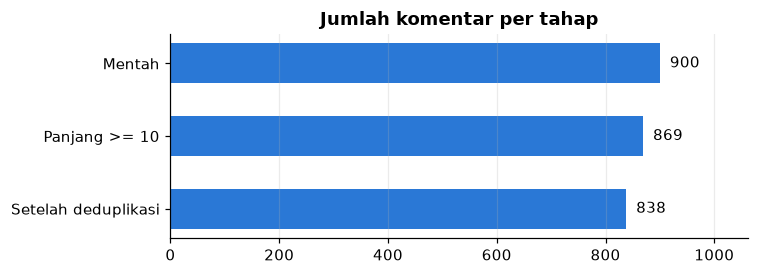

In [16]:
funnel = {"Mentah": len(df)}

df = df[df["clean_len"] >= MIN_KARAKTER]
funnel[f"Panjang >= {MIN_KARAKTER}"] = len(df)

if MAX_KARAKTER:
    df = df[df["clean_len"] <= MAX_KARAKTER]
    funnel[f"Panjang <= {MAX_KARAKTER}"] = len(df)

df["n_duplikat"] = df.groupby(["cleaned_text", "sinyal"])["cleaned_text"].transform("size")
df = df.drop_duplicates(subset=["cleaned_text", "sinyal"], keep="first")
funnel["Setelah deduplikasi"] = len(df)

funnel = pd.Series(funnel)
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(funnel.index[::-1], funnel.values[::-1], color=WARNA_MODEL[0], height=0.55)
for i, v in enumerate(funnel.values[::-1]):
    ax.text(v, i, f"  {v:,}", va="center")
ax.set_xlim(0, funnel.max() * 1.18)
ax.set_title("Jumlah komentar per tahap")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 6. EDA setelah cleaning

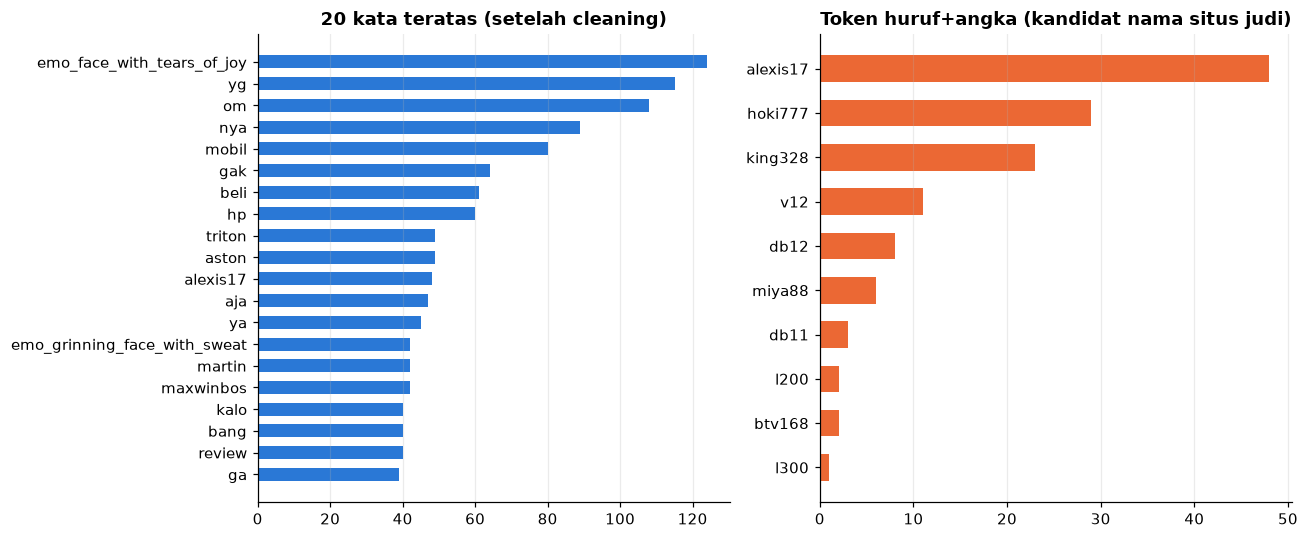

In [17]:
kata = Counter(t for t in " ".join(df["cleaned_text"]).split() if not t.startswith("xxscript")).most_common(20)
token_brand = Counter(t for s in df["cleaned_text"] for t in s.split() if re.fullmatch(r"[a-z]+\d{2,}", t)).most_common(10)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
k, f = zip(*kata)
axes[0].barh(k[::-1], f[::-1], color=WARNA_MODEL[0], height=0.6)
axes[0].set_title("20 kata teratas (setelah cleaning)")
if token_brand:
    k, f = zip(*token_brand)
    axes[1].barh(k[::-1], f[::-1], color=WARNA_LABEL[1], height=0.6)
axes[1].set_title("Token huruf+angka (kandidat nama situs judi)")
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

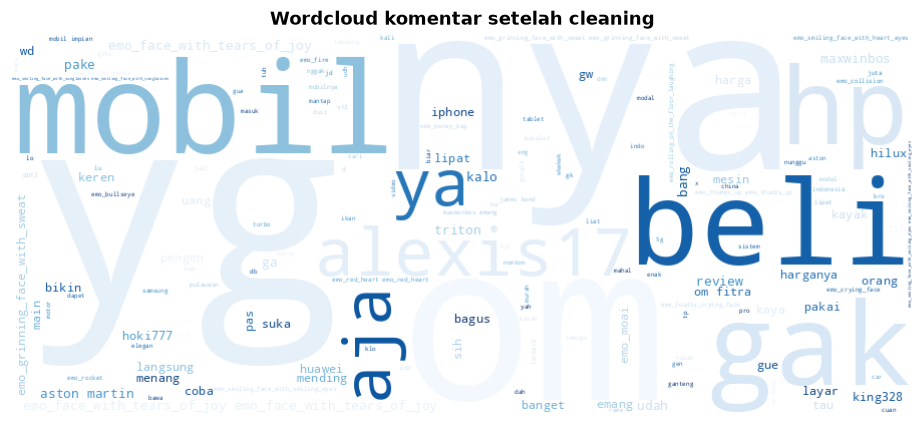

In [18]:
wc = WordCloud(width=900, height=380, background_color="white", colormap="Blues", random_state=42)
plt.figure(figsize=(11, 4.5))
plt.imshow(wc.generate(" ".join(df["cleaned_text"])), interpolation="bilinear")
plt.axis("off")
plt.title("Wordcloud komentar setelah cleaning")
plt.show()

## 7. Simpan data siap prediksi

In [19]:
KOLOM = ["video_id", "title", "channel_name", "comment_id", "author", "published_at",
         "text", "cleaned_text", "sinyal", "text_min", "n_duplikat"]
siap = df[KOLOM].reset_index(drop=True)
siap.to_csv("data_siap_predict.csv", index=False)
print(f"Disimpan: data_siap_predict.csv ({len(siap):,} baris)")
print("Kolom input model: cleaned_text + sinyal (5 model utama), ditambah text_min (model gabungan)")
siap.head()

Disimpan: data_siap_predict.csv (838 baris)
Kolom input model: cleaned_text + sinyal (5 model utama), ditambah text_min (model gabungan)


,video_id,title,channel_name,comment_id,author,published_at,text,cleaned_text,sinyal,text_min,n_duplikat
0,ufS5vDKnIhM,MITSUBISHI TRITON ULTIMATE AT | Definisi Pria Jago Di Kantor dan Di Lapangan,Motomobi,UgwcaAd6uEAYXWRfOsl4AaABAg,ayangwati9332,2026-09-27 09:42:33.235838890+00:00,"Udah dapat sih yg terbaru, selama ini belum ada kendala sih bawa muatan",udah sih yg terbaru kendala sih bawa muatan,,"udah dapat sih yg terbaru, selama ini belum ada kendala sih bawa muatan",1
1,ufS5vDKnIhM,MITSUBISHI TRITON ULTIMATE AT | Definisi Pria Jago Di Kantor dan Di Lapangan,Motomobi,UgwgUPL27H80cTO4wch4AaABAg,Sniper-GTO,2026-09-27 09:42:33.238723993+00:00,Mobil ini kalo di upgrade Tampilan pasti GANTENG Bangat.🎉,mobil kalo upgrade tampilan ganteng bangat emo_party_popper,,mobil ini kalo di upgrade tampilan pasti ganteng bangat.🎉,1
2,ufS5vDKnIhM,MITSUBISHI TRITON ULTIMATE AT | Definisi Pria Jago Di Kantor dan Di Lapangan,Motomobi,Ugx-gBe2PyGQXKi2jex4AaABAg,Zidan-y1p,2026-07-27 09:42:33.240654945+00:00,Triton udah teruji di balap tingkat dunia Rally Dakar,triton udah teruji balap tingkat dunia rally dakar,,triton udah teruji di balap tingkat dunia rally dakar,1
3,ufS5vDKnIhM,MITSUBISHI TRITON ULTIMATE AT | Definisi Pria Jago Di Kantor dan Di Lapangan,Motomobi,UgysQujcgesVRPDhXU14AaABAg,fertianeka2266,2026-07-27 09:42:33.242378950+00:00,sama hilux type v terbaru enakan mana om ...jujur yah,hilux type v terbaru enakan om jujur yah,,sama hilux type v terbaru enakan mana om ...jujur yah,1
4,ufS5vDKnIhM,MITSUBISHI TRITON ULTIMATE AT | Definisi Pria Jago Di Kantor dan Di Lapangan,Motomobi,UgyW9Fa2MqQvgs4LPoR4AaABAg,yusninurrahman6214,2026-06-27 09:42:33.244033098+00:00,❤nice ride kalo matic❤aplg dpt foglamp mcm panther 2.5 di persegi❤,emo_red_heart nice ride kalo matic emo_red_heart aplg dpt foglamp mcm panther 2 5 persegi emo_red_heart,,❤nice ride kalo matic❤aplg dpt foglamp mcm panther 2.5 di persegi❤,1


## 8. (Opsional) Prediksi dengan model dari notebook 02

Butuh folder `models/` atau file `models.zip` hasil notebook 02.
Di Colab, jalankan sel ini lalu unggah `models.zip` ketika diminta.

Seperti worker lama, hasil akhir memakai **voting mayoritas 5 model**. Model gabungan kata+karakter (yang terbaik pada
eksperimen notebook 02) ditampilkan sebagai pembanding.

In [20]:
import glob
import zipfile

import joblib

if not os.path.isdir("models") and not os.path.exists("models.zip"):
    try:
        from google.colab import files
        print("Unggah models.zip dari notebook 02:")
        files.upload()
    except ImportError:
        pass

if not os.path.isdir("models") and os.path.exists("models.zip"):
    zipfile.ZipFile("models.zip").extractall("models")

NAMA_MODEL = ["naive_bayes", "svm", "random_forest", "knn", "logistic_regression"]
ADA_MODEL = all(os.path.exists(f"models/{n}.joblib") for n in NAMA_MODEL)
print("Model ditemukan:" if ADA_MODEL else "Model belum ada - jalankan notebook 02 dulu.",
      sorted(os.path.basename(p) for p in glob.glob("models/*.joblib")))

Model ditemukan: ['gabungan_kata_karakter.joblib', 'knn.joblib', 'logistic_regression.joblib', 'naive_bayes.joblib', 'random_forest.joblib', 'svm.joblib']


In [21]:
if ADA_MODEL:
    data = pd.read_csv("data_siap_predict.csv").fillna({"cleaned_text": "", "sinyal": "", "text_min": ""})
    X = data.rename(columns={"cleaned_text": "text_clean"})[["text_clean", "sinyal", "text_min"]]
    for n in NAMA_MODEL:
        data[n] = joblib.load(f"models/{n}.joblib").predict(X)
    data["voting_5_model"] = (data[NAMA_MODEL].mean(axis=1) >= 0.5).astype(int)

    if os.path.exists("models/gabungan_kata_karakter.joblib"):
        gab = joblib.load("models/gabungan_kata_karakter.joblib")
        data["gabungan"] = gab.predict(X)

    data["is_gambling_promo"] = data["voting_5_model"].astype(bool)
    data.to_csv("hasil_prediksi.csv", index=False)

    ringkasan = data.groupby(["video_id", "title"]).agg(
        komentar=("is_gambling_promo", "size"), promosi=("is_gambling_promo", "sum"))
    ringkasan["persen_promosi"] = (ringkasan["promosi"] / ringkasan["komentar"] * 100).round(1)
    display(ringkasan)
    if "gabungan" in data:
        print(f"Kesepakatan voting vs model gabungan: {(data['voting_5_model'] == data['gabungan']).mean():.1%}")

,,komentar,promosi,persen_promosi
video_id,title,,,
VXqMJqP7mvk,HP TERGILA yang dijual RESMI di INDONESIA! - Huawei Mate XT!,283,46,16.3
gRjWM8jPIPw,"MR. BOND, MOBIL ANDA SUDAH SIAP | ASTON MARTIN DB12",272,63,23.2
ufS5vDKnIhM,MITSUBISHI TRITON ULTIMATE AT | Definisi Pria Jago Di Kantor dan Di Lapangan,283,86,30.4


Kesepakatan voting vs model gabungan: 99.0%


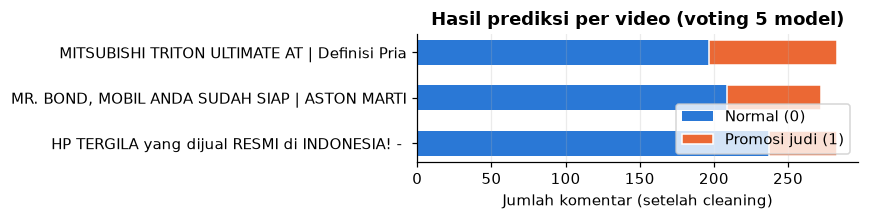

Contoh komentar yang terdeteksi promosi judi:


,text,cleaned_text,sinyal,n_duplikat,naive_bayes,svm,random_forest,knn,logistic_regression
80,mancing mnatab hanya di 𝒉𝒐𝒌𝒊777 bosku,mancing mnatab hoki777 bosku,xxfancy,1,1,1,1,1,1
81,Emang rekomendasi 07:07 lokasinya bisa langsung di cari di google ada di 【H】【o】【k】【i】【7】【7】【7】,emang rekomendasi 07 07 lokasinya langsung cari google hoki777,xxdecor xxspaced,1,1,1,1,1,1
82,ikan patin ikan sapu sapu 𝒉𝒐𝒌𝒊777 dijamin paling jitu,ikan patin ikan sapu sapu hoki777 dijamin jitu,xxfancy,1,1,1,1,1,1
91,gak pernah nyesel 𝒉𝒐𝒌𝒊777 langsung jadi banyakk boskuuu,gak nyesel hoki777 langsung banyakk boskuuu,xxfancy,1,1,1,1,1,1
92,Emang rekomendasi 07:07 Paling mantab emang baru sadar saya 【H】【o】【k】【i】【7】【7】【7】,emang rekomendasi 07 07 mantab emang sadar hoki777,xxdecor xxspaced,1,1,1,1,1,1
93,lokasinya bisa langsung di cari di google ada di 𝒉𝒐𝒌𝒊777,lokasinya langsung cari google hoki777,xxfancy,2,1,1,1,1,1
94,mancing mnatab hanya di 【H】【o】【k】【i】【7】【7】【7】 bosku Emang rekomendasi 07:07,mancing mnatab hoki777 bosku emang rekomendasi 07 07,xxdecor xxspaced,1,1,1,1,1,1
95,Tunggu apa lagi kemaren gua juga udah cobain 𝒉𝒐𝒌𝒊777 manteb banget Emang rekomendasi 07:07,tunggu kemaren gua udah cobain hoki777 manteb banget emang rekomendasi 07 07,xxfancy,1,1,1,1,1,1
96,"Emang rekomendasi 07:07 gak kerasa bentar lagi hari raya , jadi jangan lupa juga untuk coba 𝒉𝒐𝒌𝒊777",emang rekomendasi 07 07 gak kerasa bentar raya lupa coba hoki777,xxfancy,1,1,1,1,1,1
97,stock di lapak 𝒉𝒐𝒌𝒊777 juga buwanyak sekali bangg,stock lapak hoki777 buwanyak bangg,xxfancy,1,1,1,1,1,1


Contoh komentar yang dianggap normal:


,text,cleaned_text
0,"Udah dapat sih yg terbaru, selama ini belum ada kendala sih bawa muatan",udah sih yg terbaru kendala sih bawa muatan
1,Mobil ini kalo di upgrade Tampilan pasti GANTENG Bangat.🎉,mobil kalo upgrade tampilan ganteng bangat emo_party_popper
2,Triton udah teruji di balap tingkat dunia Rally Dakar,triton udah teruji balap tingkat dunia rally dakar
3,sama hilux type v terbaru enakan mana om ...jujur yah,hilux type v terbaru enakan om jujur yah
4,❤nice ride kalo matic❤aplg dpt foglamp mcm panther 2.5 di persegi❤,emo_red_heart nice ride kalo matic emo_red_heart aplg dpt foglamp mcm panther 2 5 persegi emo_red_heart
5,Triton The Best,triton the best
6,"Sebenarnya pingin nonton sampai tuntas, tapi itu yg make masker gayanya membuat saya ngak sreg",pingin nonton tuntas yg make masker gayanya ngak sreg
7,Mitsubishi Triton Ultimate,mitsubishi triton ultimate
8,Om mobi spil jam tangannya om,om mobi spil jam tangannya om
9,Allahhummasyallialamuhammad 11:26,allahhummasyallialamuhammad 11 26


In [22]:
if ADA_MODEL:
    fig, ax = plt.subplots(figsize=(8, 0.6 + 0.5 * len(ringkasan)))
    label_video = [str(t)[:45] for t in ringkasan.index.get_level_values("title")]
    normal = ringkasan["komentar"] - ringkasan["promosi"]
    ax.barh(label_video, normal, color=WARNA_LABEL[0], height=0.55, label=NAMA_LABEL[0])
    ax.barh(label_video, ringkasan["promosi"], left=normal, color=WARNA_LABEL[1], height=0.55,
            label=NAMA_LABEL[1], edgecolor="white", linewidth=1)
    ax.set_xlabel("Jumlah komentar (setelah cleaning)")
    ax.set_title("Hasil prediksi per video (voting 5 model)")
    ax.legend(loc="lower right")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()

    print("Contoh komentar yang terdeteksi promosi judi:")
    display(data.loc[data["is_gambling_promo"], ["text", "cleaned_text", "sinyal", "n_duplikat"] + NAMA_MODEL].head(15))
    print("Contoh komentar yang dianggap normal:")
    display(data.loc[~data["is_gambling_promo"], ["text", "cleaned_text"]].head(10))

## Catatan

- File hasil: `komentar_mentah.csv`, `data_siap_predict.csv`, dan (jika model tersedia) `hasil_prediksi.csv`.
- Video contoh berasal dari dataset training, jadi komentarnya sebagian sudah pernah "dilihat" model. Untuk menguji
  kemampuan sebenarnya, gunakan video baru.
- Waktu komentar (`published_at`) hanya perkiraan karena YouTube menampilkan waktu relatif ("2 minggu yang lalu").